---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pick an analytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

In [17]:
#a
def f(x):
    return x**2 - 4
def bisection(f, a, b, tol=1e-6):
    iterations = 0

    while abs(b - a) > tol:
        c = (a + b) / 2
        iterations += 1

        if abs(f(c)) < tol:
            return c, iterations

        if f(a) * f(c) < 0:
            b = c
        else:
            a = c

    return (a + b) / 2, iterations

def secant(f, x0, x1, tol=1e-6):
    iterations = 0
    while abs(x1 - x0) > tol:
        x2 = x1 - f(x1) * (x1 - x0) / (f(x1) - f(x0))
        x0 = x1
        x1 = x2
        iterations += 1
    return x1, iterations

def false_position(f, a, b, tol=1e-6):
    iterations = 0
    while True:
        c = b - f(b) * (b - a) / (f(b) - f(a))
        iterations += 1
        if abs(f(c)) < tol:
            return c, iterations

        if f(a) * f(c) < 0:
            b = c
        else:
            a = c

def df(x):
    return 2*x
    
def newton(f, df, x0, tol=1e-6):
    iterations = 0

    while abs(f(x0)) > tol:
        x0 = x0 - f(x0) / df(x0)
        iterations += 1

    return x0, iterations

print("Bisection:", bisection(f, 1, 3))
print("Secant:", secant(f, 1, 3))
print("False position:", false_position(f, 1, 3))
print("Newton-Raphson:", newton(f, df, 3))

Bisection: (2.0, 1)
Secant: (2.0000000000004996, 6)
False position: (1.9999998634666714, 10)
Newton-Raphson: (2.000000000026214, 4)


In [16]:
#b
def f(x):
    return np.exp(x) - 1 - x - x**2 / 2

def df(x):
    return np.exp(x) - 1 - x
    
root_bis, iter_bis = bisection(f, -1, 2)
root_sec, iter_sec = secant(f, -1, 2)
root_false, iter_false = false_position(f, -1, 2)
root_newton, iter_newton = newton(f, df, 2)

print("Bisection:", root_bis, "Iterations:", iter_bis)
print("Secant:", root_sec, "Iterations:", iter_sec)
print("False position:", root_false, "Iterations:", iter_false)
print("Newton-Raphson:", root_newton, "Iterations:", iter_newton)

Bisection: -0.015625 Iterations: 6
Secant: -6.166793775670411e-06 Iterations: 46
False position: -0.018198489955734587 Iterations: 10718
Newton-Raphson: 1.4556788418556055 Iterations: 1


## c)
#### The four methods find approximately the same root. But they need different numbers of iterations.

#### The Newton-Raphson method is i think the fastest, because it uses the derivative of the function so it usually converges quickly when the starting point is chosen good.

#### The secant method is a bit similar to Newton-Raphson, but it does not require the derivative. It is usually also fast, but its convergence depends more on the chosen starting points.

#### The bisection method is slower but also very reliable. Because it repeatedly divides an interval containing the root in half.

#### The false position method also keeps the root inside an interval, but chooses the next point using a straight line between the endpoints.

#### So the choice of starting points is important. Good starting points close to the root can reduce the number of iterations, especially for Newton-Raphson and the secant method.

## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

In [4]:
#a
A = np.array([[5, 3],
              [1, -4]])

b = np.array([15, -2])

print("A =")
print(A)

print("b =")
print(b)

A =
[[ 5  3]
 [ 1 -4]]
b =
[15 -2]


In [5]:
#b
from scipy.linalg import lu

P, L, U = lu(A)

print("L =")
print(L)
print("U =")
print(U)

x = np.linalg.solve(A, b)

print("Solution:")
print("x1 =", x[0])
print("x2 =", x[1])
print("Check:")
print(A @ x)

L =
[[1.  0. ]
 [0.2 1. ]]
U =
[[ 5.   3. ]
 [ 0.  -4.6]]
Solution:
x1 = 2.347826086956522
x2 = 1.0869565217391306
Check:
[15. -2.]


In [8]:
#c
A = np.array([[1, -4],
              [5,  3]])
b = np.array([3, -7])
x = np.linalg.solve(A, b)

print("x1 =", x[0])
print("x2 =", x[1])
print("Check:", A @ x)
# We first put the coefficients into matrix A and the right-hand sides into vector b.
# Then np.linalg.solve(A, b) directly solves Ax=b. 
# The final check confirms to us that the calculated x_1,x_2 reproduce the original right-hand side.

x1 = -0.8260869565217391
x2 = -0.9565217391304349
Check: [ 3. -7.]


## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how many times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.

In [9]:
#a
x = np.linspace(-2, 2, 400)
y = np.linspace(-2, 2, 400)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

print(Z)

[[-2.        -2.j         -1.98997494-2.j         -1.97994987-2.j
  ...  1.97994987-2.j          1.98997494-2.j
   2.        -2.j        ]
 [-2.        -1.98997494j -1.98997494-1.98997494j -1.97994987-1.98997494j
  ...  1.97994987-1.98997494j  1.98997494-1.98997494j
   2.        -1.98997494j]
 [-2.        -1.97994987j -1.98997494-1.97994987j -1.97994987-1.97994987j
  ...  1.97994987-1.97994987j  1.98997494-1.97994987j
   2.        -1.97994987j]
 ...
 [-2.        +1.97994987j -1.98997494+1.97994987j -1.97994987+1.97994987j
  ...  1.97994987+1.97994987j  1.98997494+1.97994987j
   2.        +1.97994987j]
 [-2.        +1.98997494j -1.98997494+1.98997494j -1.97994987+1.98997494j
  ...  1.97994987+1.98997494j  1.98997494+1.98997494j
   2.        +1.98997494j]
 [-2.        +2.j         -1.98997494+2.j         -1.97994987+2.j
  ...  1.97994987+2.j          1.98997494+2.j
   2.        +2.j        ]]


In [10]:
#b
Z_new = Z.copy()
n_iter = 50
for i in range(n_iter):
    Z_new = Z_new - (Z_new**3 - 1) / (3 * Z_new**2)

print(Z_new)

[[-0.5-0.8660254j -0.5-0.8660254j -0.5-0.8660254j ...  1. +0.j
   1. +0.j         1. +0.j       ]
 [-0.5-0.8660254j -0.5-0.8660254j -0.5-0.8660254j ...  1. +0.j
   1. +0.j         1. +0.j       ]
 [-0.5-0.8660254j -0.5-0.8660254j -0.5-0.8660254j ...  1. +0.j
   1. +0.j         1. +0.j       ]
 ...
 [-0.5+0.8660254j -0.5+0.8660254j -0.5+0.8660254j ...  1. +0.j
   1. +0.j         1. +0.j       ]
 [-0.5+0.8660254j -0.5+0.8660254j -0.5+0.8660254j ...  1. +0.j
   1. +0.j         1. +0.j       ]
 [-0.5+0.8660254j -0.5+0.8660254j -0.5+0.8660254j ...  1. +0.j
   1. +0.j         1. +0.j       ]]


In [11]:
#c
roots = np.array([
    1,
    -0.5 + 1j * np.sqrt(3)/2,
    -0.5 - 1j * np.sqrt(3)/2
])
d0 = np.abs(Z_new - roots[0])
d1 = np.abs(Z_new - roots[1])
d2 = np.abs(Z_new - roots[2])
nearest_root = np.argmin([d0, d1, d2], axis=0)

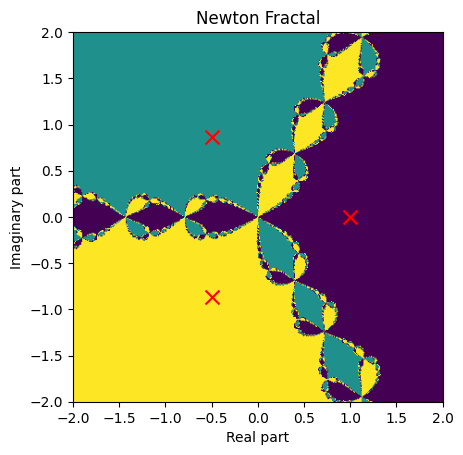

In [12]:
#d
plt.imshow(nearest_root, extent=[-2, 2, -2, 2],
           origin="lower", cmap="viridis")
plt.scatter(roots.real, roots.imag,
            color="red", marker="x", s=100)
plt.xlabel("Real part")
plt.ylabel("Imaginary part")
plt.title("Newton Fractal")
plt.show()